# 04 – Teden 6: sezonski trendi, hipoteze in statistični testi

**Vsebina:**
1. Obstoječe analize o razporeditvi prenočitev čez leto v Južni Tirolski, Italiji in Švici ter primerjava z našimi podatki.
2. Nadaljevanje vizualizacij: ali se sezonskost s časom zmanjšuje, kateri meseci rastejo, kako se razvijata zimska in poletna sezona.
3. Zasnova hipotez, izbira statističnih testov in prvi izračun.

Nabor je isti kot v zvezkih 02 in 03 (hoteli, Južna Tirolska in Švica, 2013–2025, prag 1000 m, občine z vsaj 95 % mesecev).
Za primerjavo z uradnimi objavami uporabimo tudi vse nastanitve (ASTAT `all`, ISTAT).
Obdobje **pred** covidom je 2013–2019, obdobje **po** covidu 2023–2025 (leto 2022 izpustimo, ker so v Italiji do pomladi še veljale omejitve).

Vsi izračuni so v drugi celici; ko sta prvi dve celici zagnani, lahko ostale celice zaganjamo v poljubnem vrstnem redu.

Države, ki jih prikazujemo, so določene na enem mestu: slovar `COUNTRIES` v prvi celici s kodo. Novo državo dodamo tam (glej `DODAJANJE_PODATKOV.md`).

In [1]:
import math
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
ALT_MIN = 1000
YEARS = (2013, 2025)
COVID = [2020, 2021]
PRE, POST = list(range(2013, 2020)), [2023, 2024, 2025]
WINTER, SUMMER = [12, 1, 2, 3], [6, 7, 8, 9]
MONTHS = ["jan", "feb", "mar", "apr", "maj", "jun", "jul", "avg", "sep", "okt", "nov", "dec"]

# Countries shown in every chart and test, in display order.
# To add a country: add its code (the `country` column of tourism_monthly.csv) and label here.
COUNTRIES = {"IT": "Italija (Južna Tirolska)", "CH": "Švica"}
# categorical colours, assigned in the order above (first three are colour-blind safe as a set)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
assert len(COUNTRIES) <= len(PALETTE), "add a colour to PALETTE"
COLORS = dict(zip(COUNTRIES, PALETTE))
LABELS = COUNTRIES
INK, MUTED, GRID, PRE_COLOR = "#0b0b0b", "#52514e", "#e4e3df", "#9a9893"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")


def gini(x):
    """Gini index of the 12 monthly values: 0 = equal every month, higher = more concentrated."""
    x = np.asarray(x, float)
    return np.abs(x[:, None] - x[None, :]).sum() / (2 * len(x) ** 2 * x.mean())


# --- non-parametric tests, written with numpy (scipy is not installed);
# results match scipy.stats (spearmanr, mannwhitneyu, wilcoxon, kruskal) with the normal approximation
def _ranks(x):
    return pd.Series(x).rank().to_numpy()

def _tie_sum(x):
    _, t = np.unique(x, return_counts=True)
    return (t ** 3 - t).sum()

def _norm_sf(z):
    return 0.5 * math.erfc(z / math.sqrt(2))

def spearman_test(x, y, alternative="two-sided", n_perm=10_000, seed=1):
    """Spearman rho with a permutation p-value."""
    rx, ry = _ranks(x), _ranks(y)
    rho = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(seed)
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(n_perm)])
    hits = {"greater": perm >= rho, "less": perm <= rho, "two-sided": np.abs(perm) >= abs(rho)}[alternative]
    return rho, (hits.sum() + 1) / (n_perm + 1)

def mann_whitney(x, y):
    """Two-sided Mann-Whitney U (normal approximation, tie-corrected). Effect size r = |z| / sqrt(N)."""
    x, y = np.asarray(x), np.asarray(y)
    n1, n2 = len(x), len(y)
    allv = np.concatenate([x, y])
    N = n1 + n2
    u = _ranks(allv)[:n1].sum() - n1 * (n1 + 1) / 2
    sigma = math.sqrt(n1 * n2 / 12 * ((N + 1) - _tie_sum(allv) / (N * (N - 1))))
    z = (u - n1 * n2 / 2) / sigma
    return u, 2 * _norm_sf(abs(z)), abs(z) / math.sqrt(N)

def wilcoxon_signed(d, alternative="two-sided"):
    """Wilcoxon signed-rank test of the paired differences d (zeros dropped). Effect size r = |z| / sqrt(n)."""
    d = np.asarray(d, float)
    d = d[d != 0]
    n = len(d)
    r = _ranks(np.abs(d))
    w = r[d > 0].sum()
    sigma = math.sqrt(n * (n + 1) * (2 * n + 1) / 24 - _tie_sum(np.abs(d)) / 48)
    z = (w - n * (n + 1) / 4) / sigma
    p = {"greater": _norm_sf(z), "less": _norm_sf(-z), "two-sided": 2 * _norm_sf(abs(z))}[alternative]
    return w, p, abs(z) / math.sqrt(n)

def kruskal_wallis(groups):
    """Kruskal-Wallis H for three groups (chi-square with 2 df has the closed form sf = exp(-H/2)).
    Effect size epsilon^2 = H / (N - 1)."""
    assert len(groups) == 3
    allv = np.concatenate(groups)
    N = len(allv)
    r = _ranks(allv)
    h, start = 0.0, 0
    for g in groups:
        h += r[start:start + len(g)].sum() ** 2 / len(g)
        start += len(g)
    h = 12 / (N * (N + 1)) * h - 3 * (N + 1)
    h /= 1 - _tie_sum(allv) / (N ** 3 - N)
    return h, math.exp(-h / 2), h / (N - 1)

def holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for i, k in enumerate(order):
        running = max(running, (len(p) - i) * p[k])
        adj[k] = min(1.0, running)
    return adj

In [2]:
df = pd.read_csv(ROOT / "data/processed/tourism_monthly.csv", dtype={"muni_id": str}, parse_dates=["date"])
hot = df[(df["scope"] == "hotel") & df["country"].isin(COUNTRIES) & df["year"].between(*YEARS)].copy()
normal = hot[~hot["year"].isin(COVID)]
coverage = normal.groupby(["country", "muni_id"])["overnights"].count() / normal["date"].nunique()
keep = coverage[coverage >= 0.95].index
hot = hot.set_index(["country", "muni_id"]).loc[keep].reset_index()
hot["high"] = hot["elev_m"] >= ALT_MIN
hot["season"] = np.where(hot["month"] == 12, hot["year"] + 1, hot["year"])   # Dec counts to next winter
normal = hot[~hot["year"].isin(COVID)]

# --- one row per municipality: elevation and winter share (as in notebook 03)
muni = (normal.groupby(["country", "muni_id"])
              .agg(name=("muni_name", "first"), elev_m=("elev_m", "first"), total=("overnights", "sum")))
muni["winter_share"] = (normal[normal["month"].isin(WINTER)]
                        .groupby(["country", "muni_id"])["overnights"].sum() / muni["total"])
muni = muni.dropna(subset=["elev_m", "winter_share"])
muni["high"] = muni["elev_m"] >= ALT_MIN

# --- Gini of the monthly distribution per year, aggregated over the municipalities of a band (section 2a)
agg = hot.groupby(["country", "high", "year", "month"])["overnights"].sum().reset_index()
gini_year = agg.groupby(["country", "high", "year"])["overnights"].apply(gini).unstack(["country", "high"])
gini_year.loc[COVID] = np.nan

# --- average monthly share of annual overnights, before and after COVID, high municipalities (section 2b)
hi = agg[agg["high"]].copy()
hi["share"] = hi["overnights"] / hi.groupby(["country", "year"])["overnights"].transform("sum")
share_pp = pd.concat({"pre": hi[hi["year"].isin(PRE)].groupby(["country", "month"])["share"].mean(),
                      "post": hi[hi["year"].isin(POST)].groupby(["country", "month"])["share"].mean()}, axis=1)
share_pp["diff"] = share_pp["post"] - share_pp["pre"]

# --- winter (Dec-Mar) and summer (Jun-Sep) totals of high municipalities, index: 2014-2019 mean = 100 (section 2c)
h = hot[hot["high"]]
win_tot = h[h["month"].isin(WINTER)].groupby(["country", "season"])["overnights"].sum().unstack(0)
sum_tot = h[h["month"].isin(SUMMER)].groupby(["country", "year"])["overnights"].sum().unstack(0)
win_tot = win_tot.loc[2014:2025]   # winter 2013 lacks Dec 2012, winter 2026 is not finished
sum_tot = sum_tot.loc[2014:2025]
win_idx = win_tot / win_tot.loc[2014:2019].mean() * 100
sum_idx = sum_tot / sum_tot.loc[2014:2019].mean() * 100
win_idx.loc[COVID] = np.nan
sum_idx.loc[COVID] = np.nan

# --- per municipality: Gini before vs after COVID, and growth of winter vs summer (sections 2d, 3)
def monthly_profile(years):
    return hot[hot["year"].isin(years)].groupby(["country", "muni_id", "month"])["overnights"].mean().unstack().dropna()

prof_pre, prof_post = monthly_profile(PRE), monthly_profile(POST)
both = prof_pre.index.intersection(prof_post.index)
change = pd.DataFrame({"gini_pre": prof_pre.loc[both].apply(gini, axis=1),
                       "gini_post": prof_post.loc[both].apply(gini, axis=1)})
change["gini_diff"] = change["gini_post"] - change["gini_pre"]

W = hot[hot["month"].isin(WINTER)].groupby(["country", "muni_id", "season"])["overnights"].sum(min_count=4).unstack()
S = hot[hot["month"].isin(SUMMER)].groupby(["country", "muni_id", "year"])["overnights"].sum(min_count=4).unstack()
change["winter_growth"] = np.log(W[POST].mean(axis=1) / W[[2014, 2015, 2016, 2017, 2018, 2019]].mean(axis=1))
change["summer_growth"] = np.log(S[POST].mean(axis=1) / S[PRE].mean(axis=1))
change["summer_minus_winter"] = change["summer_growth"] - change["winter_growth"]
change = change.join(muni[["name", "elev_m", "high"]], how="inner").reset_index()

# --- year-to-year volatility of winter overnights (as in notebook 03), for H3
OK_WINTER = [2014, 2015, 2016, 2017, 2018, 2019, 2023, 2024, 2025]
w_ok = np.log(W[OK_WINTER])
w_diff = w_ok.diff(axis=1)[[y for y in OK_WINTER if y - 1 in OK_WINTER]]
vol = w_diff.std(axis=1).rename("winter_vol").to_frame().join(muni[["elev_m"]], how="inner").dropna()
vol["band"] = pd.cut(vol["elev_m"], [0, 600, 1000, 4000], labels=["< 600 m", "600–1000 m", "≥ 1000 m"], right=False)

change.groupby(["country", "high"])[["gini_pre", "gini_post", "gini_diff", "winter_growth", "summer_growth"]].median().round(3)

gini_pre  gini_post  gini_diff  winter_growth  summer_growth
country high                                                               
CH      False     0.153      0.168      0.005          0.064          0.127
        True      0.303      0.262     -0.028          0.084          0.131
IT      False     0.327      0.310     -0.019          0.096          0.022
        True      0.364      0.329     -0.034          0.116          0.118

## 1. Obstoječe analize o razporeditvi prenočitev čez leto

| # | Vir | Kaj ugotavlja | Kako primerjamo |
|---|---|---|---|
| 1 | **Eurac Research, Sustainable Tourism Observatory (STOST)**, letna poročila 2022 in 2023 (Južna Tirolska) | približno 60 % gostov poleti in 40 % pozimi; vrh avgusta ali februarja, posamezen mesec lahko prinese 17 % ali več letnih prihodov; vzorec je bil pred pandemijo 10 let razmeroma stabilen | delež maj–oktober in najmočnejši mesec v ASTAT (vse nastanitve) |
| 2 | **ISTAT, Movimento turistico 2024** (vsa Italija) | rekordnih 466,2 mio. prenočitev; avgust je najbolj turističen mesec (81 mio., okoli 17 %), julij je vrh za tuje goste | delež avgusta v ISTAT 2024, vsa Italija in Južna Tirolska |
| 3 | **BFS, sporočila 2025–2026** (Švica, hoteli) | poletje 2025 (maj–okt) rekordnih 25,1 mio., tretje rekordno poletje zapored; zima 2024/25 (nov–apr) rekordnih 18,6 mio.; leto 2025 43,9 mio. | razmerje poletje/zima in rekordi v naših 186 občinah |
| 4 | **Serquet in Rebetez (2011)**, *Climatic Change* 108, 291–300 | v vročih poletjih je v 40 švicarskih alpskih krajih več prenočitev; učinek je najmočnejši junija, najbližje mestom | rast junija in poletja v visokih občinah (posredno, brez temperatur) |
| 5 | **Fernández-Morales (2003)**, *Annals of Tourism Research* 30(4), 942–956 | Ginijev koeficient kot mera sezonske koncentracije | metoda, ki jo uporabimo v razdelku 2 |
| 6 | **Južna Tirolska, deželni koncept razvoja turizma (LTEK 2030+), »Bettenstopp«** (stol.it) | omejitev števila postelj na raven 2019; rast naj pride iz boljše zasedenosti in daljših sezon, ne iz več postelj | ali se sezonskost po letu 2019 zmanjšuje (Gini, rast izven sezone) |

Spodaj preverimo vire 1–3 neposredno z našimi podatki.

In [3]:
st_all = df[(df["source"] == "ASTAT") & (df["scope"] == "all")]
st_m = st_all.groupby(["year", "month"])["overnights"].sum().unstack()
st_share = st_m.div(st_m.sum(axis=1), axis=0)

istat24 = df[(df["source"] == "ISTAT") & (df["year"] == 2024)]
it_m = istat24.groupby("month")["overnights"].sum()
bz_m = istat24[istat24["region"] == "BOLZANO - BOZEN"].groupby("month")["overnights"].sum()

ch = df[df["source"] == "BFS"]
def ch_period(start, end):   # inclusive, "YYYY-MM"
    return ch[(ch["date"] >= start) & (ch["date"] <= end)]["overnights"].sum() / 1e6

ch_summer = {y: ch_period(f"{y}-05-01", f"{y}-10-01") for y in range(2013, 2026)}
ch_winter = {y: ch_period(f"{y - 1}-11-01", f"{y}-04-01") for y in range(2014, 2026)}

rows = [
    ("JT: delež maj–okt (vse nastanitve), 2013–2019", "≈ 60 % (Eurac)", f"{st_share.loc[PRE, 5:10].sum(axis=1).mean():.0%}"),
    ("JT: delež maj–okt, 2023–2025", "≈ 60 % (Eurac, UniBZ 2024)", f"{st_share.loc[POST, 5:10].sum(axis=1).mean():.0%}"),
    ("JT: najmočnejši mesec, delež (2023–2025)", "avgust, ≥ 17 %",
     f"{MONTHS[int(st_share.loc[POST].mean().idxmax()) - 1]}, {st_share.loc[POST].mean().max():.0%}"),
    ("Italija 2024: prenočitve skupaj (mio.)", "466,2 (ISTAT)", f"{it_m.sum() / 1e6:.1f}"),
    ("Italija 2024: delež avgusta", "≈ 17 % (81 / 466,2)", f"{it_m[8] / it_m.sum():.1%}"),
    ("Južna Tirolska 2024 (ISTAT): delež avgusta", "–", f"{bz_m[8] / bz_m.sum():.1%}"),
    ("CH poletje 2025 (maj–okt), mio.", "25,1 (vsa CH, rekord)", f"{ch_summer[2025]:.1f} (rekord: {max(ch_summer, key=ch_summer.get)})"),
    ("CH zima 2024/25 (nov–apr), mio.", "18,6 (vsa CH, rekord)", f"{ch_winter[2025]:.1f} (rekord: {max(ch_winter, key=ch_winter.get) - 1}/{str(max(ch_winter, key=ch_winter.get))[2:]})"),
    ("CH razmerje poletje / zima 2025", f"{25.1 / 18.6:.2f}", f"{ch_summer[2025] / ch_winter[2025]:.2f}"),
]
pd.DataFrame(rows, columns=["kazalnik", "obstoječa analiza", "naši podatki"])

,kazalnik,obstoječa analiza,naši podatki
0,"JT: delež maj–okt (vse nastanitve), 2013–2019",≈ 60 % (Eurac),62%
1,"JT: delež maj–okt, 2023–2025","≈ 60 % (Eurac, UniBZ 2024)",62%
2,"JT: najmočnejši mesec, delež (2023–2025)","avgust, ≥ 17 %","avg, 16%"
3,Italija 2024: prenočitve skupaj (mio.),"466,2 (ISTAT)",442.5
4,Italija 2024: delež avgusta,"≈ 17 % (81 / 466,2)",17.8%
5,Južna Tirolska 2024 (ISTAT): delež avgusta,–,16.3%
6,"CH poletje 2025 (maj–okt), mio.","25,1 (vsa CH, rekord)",19.9 (rekord: 2025)
7,"CH zima 2024/25 (nov–apr), mio.","18,6 (vsa CH, rekord)",15.1 (rekord: 2024/25)
8,CH razmerje poletje / zima 2025,1.35,1.32


**Opažanja:**
- **Eurac (Južna Tirolska):** maj–oktober prinese 62 % prenočitev v vseh nastanitvah, pred covidom in po njem enako. To se ujema z Eurac (okoli 60 % poleti). Najmočnejši mesec je avgust s 16 % (Eurac: 17 % ali več, a za prihode, ne prenočitve).
- **ISTAT (vsa Italija 2024):** naši podatki dajo 442,5 mio. prenočitev, ISTAT jih objavlja 466,2 mio. Razlika (5 %) so zaupne občine, ki v občinski tabeli manjkajo. Delež avgusta je 17,8 % (ISTAT: 81 / 466,2 = 17,4 %). Južna Tirolska je z 16,3 % malo manj zgoščena v avgustu kot Italija kot celota, ker ima še zimsko sezono.
- **BFS (Švica):** naših 186 občin ima poleti 2025 19,9 mio. in pozimi 2024/25 15,1 mio. prenočitev (okoli 80 % vse Švice). Tako kot pri BFS sta obe sezoni 2025 rekordni. Razmerje poletje/zima je 1,32, pri BFS 1,35.
- Viri 4–6 govorijo o spremembah sezonskosti (vročina v nižinah, daljše sezone). Te preverimo v razdelkih 2 in 3.

## 2. Nadaljevanje vizualizacij: kako se spreminja sezonskost

### 2a. Ginijev koeficient sezonske koncentracije po letih

Za vsako leto izračunamo Ginijev koeficient 12 mesečnih vsot (Fernández-Morales, 2003): 0 pomeni enako število prenočitev vsak mesec, višja vrednost pa, da je obisk zgoščen v nekaj mesecih. Leti 2020–2021 izpustimo.

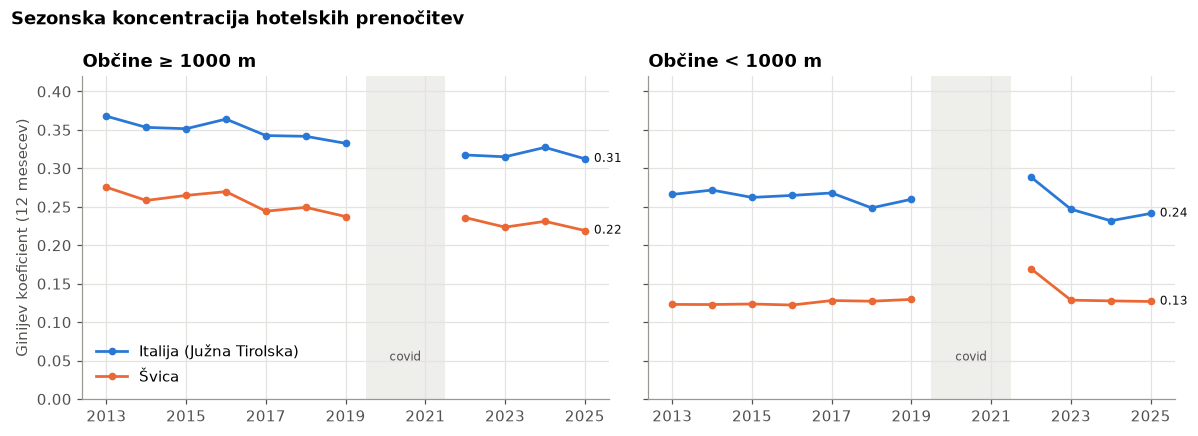

country              CH            IT       
high              False  True   False  True 
year                                        
po (2023–2025)    0.128  0.225  0.240  0.318
pred (2013–2019)  0.125  0.257  0.263  0.351

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, is_high, title in [(axes[0], True, f"Občine ≥ {ALT_MIN} m"), (axes[1], False, f"Občine < {ALT_MIN} m")]:
    for c in COUNTRIES:
        s = gini_year[(c, is_high)]
        ax.plot(s.index, s, color=COLORS[c], lw=1.8, marker="o", ms=4, label=LABELS[c])
        ax.annotate(f"{s.dropna().iloc[-1]:.2f}", (s.dropna().index[-1], s.dropna().iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
    ax.axvspan(2019.5, 2021.5, color=GRID, alpha=0.6, lw=0)
    ax.text(2020.5, 0.05, "covid", ha="center", fontsize=8, color=MUTED)
    ax.set_title(title, loc="left")
    ax.set_xticks(range(2013, 2026, 2))
axes[0].set_ylim(0, 0.42)
axes[0].set_ylabel("Ginijev koeficient (12 mesecev)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Sezonska koncentracija hotelskih prenočitev", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

gini_year.loc[PRE + POST].groupby(lambda y: "pred (2013–2019)" if y < 2020 else "po (2023–2025)").mean().round(3)

**Opažanja:**
- V visokih občinah se sezonska koncentracija zmanjšuje v obeh državah: v Južni Tirolski z 0,35 (2013–2019) na 0,32 (2023–2025), v Švici z 0,26 na 0,23. Upad se je začel že pred covidom (Švica od leta 2016) in se po njem nadaljuje.
- Južna Tirolska je v obeh višinskih pasovih bolj sezonska kot Švica. Švicarske nizke občine so skoraj enakomerne (Gini 0,13), ker so v njih mesta s poslovnim turizmom.
- Leto 2022 je pri nizkih občinah izjema: zaradi omejitev v začetku leta je bil obisk bolj zgoščen v poletje. Zato ga v primerjavi pred/po ne upoštevamo.
- Eurac je za obdobje pred pandemijo zapisal, da je sezonski vzorec stabilen. Naši podatki kažejo počasno, a vztrajno zmanjševanje koncentracije, ki ga pri prihodih na ravni cele dežele morda ni videti.

### 2b. Kateri meseci so pridobili: delež letnih prenočitev pred in po covidu

Za visoke občine primerjamo povprečni delež vsakega meseca v letih 2013–2019 (siva) in 2023–2025 (barva). Črta med točkama je sprememba.

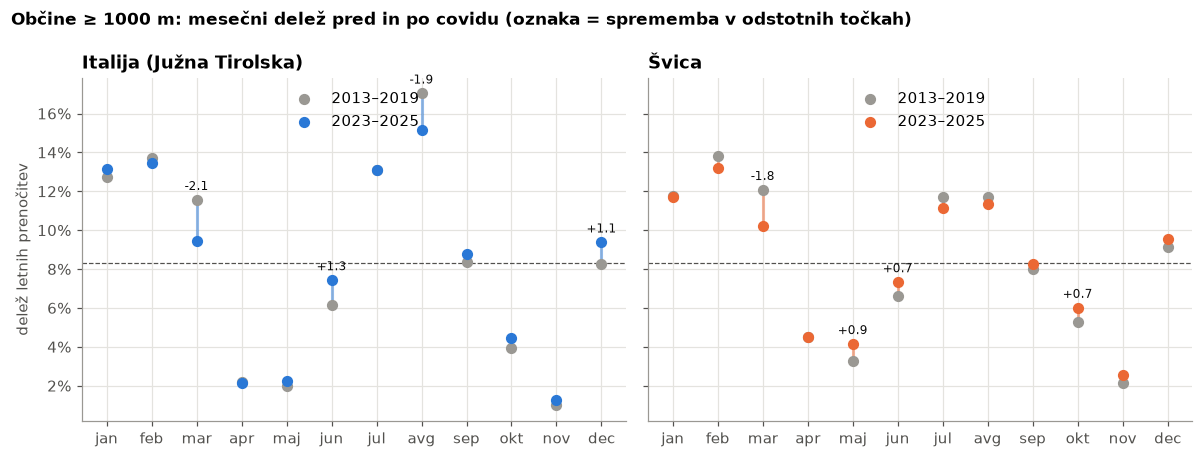

In [5]:
fig, axes = plt.subplots(1, len(COUNTRIES), figsize=(5.5 * len(COUNTRIES), 4.2), sharey=True, squeeze=False)
axes = axes.ravel()
for ax, c in zip(axes, COUNTRIES):
    s = share_pp.loc[c]
    x = s.index.to_numpy()
    ax.vlines(x, s["pre"], s["post"], color=COLORS[c], lw=2, alpha=0.5)
    ax.scatter(x, s["pre"], s=40, color=PRE_COLOR, zorder=3, label="2013–2019")
    ax.scatter(x, s["post"], s=40, color=COLORS[c], zorder=3, label="2023–2025")
    for m in x:
        d = s.loc[m, "diff"]
        if abs(d) >= 0.006:
            ax.text(m, max(s.loc[m, "pre"], s.loc[m, "post"]) + 0.005, f"{d * 100:+.1f}", ha="center",
                    fontsize=8, color=INK)
    ax.axhline(1 / 12, color=MUTED, lw=0.8, ls="--")
    ax.set_xticks(range(1, 13), MONTHS)
    ax.set_title(LABELS[c], loc="left")
    ax.legend(frameon=False, loc="upper center")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylabel("delež letnih prenočitev")
fig.suptitle(f"Občine ≥ {ALT_MIN} m: mesečni delež pred in po covidu (oznaka = sprememba v odstotnih točkah)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Opažanja:**
- **Južna Tirolska:** avgust je izgubil 1,9 odstotne točke deleža, marec 2,1. Pridobila sta junij (+1,3) in december (+1,1). Poletni vrh se razširja na junij, zima pa se seli od marca proti decembru.
- **Švica:** pridobili so maj (+0,9), junij (+0,7) in oktober (+0,7), izgubil pa je marec (−1,8). Rast je predvsem v predsezoni in posezoni.
- Upad marca je delno posledica datuma velike noči: pred covidom je bila velika noč trikrat v marcu ali na 1. april (2013, 2016, 2018), v letih 2023–2025 pa večinoma v aprilu. Ker so aprili v visokih občinah kljub temu skoraj nespremenjeni, je verjetno vpliv tudi krajša smučarska sezona ob koncu zime.
- Rast junija se ujema s Serquet in Rebetez (2011), po katerih vročina v nižinah najbolj poveča obisk gora prav junija. Brez temperaturnih podatkov tega ne moremo potrditi.

### 2c. Zimska in poletna sezona skozi čas

Indeks prenočitev v visokih občinah (povprečje 2014–2019 = 100) za zimo (december–marec, označeno z letom, v katerem se zima konča) in poletje (junij–september).

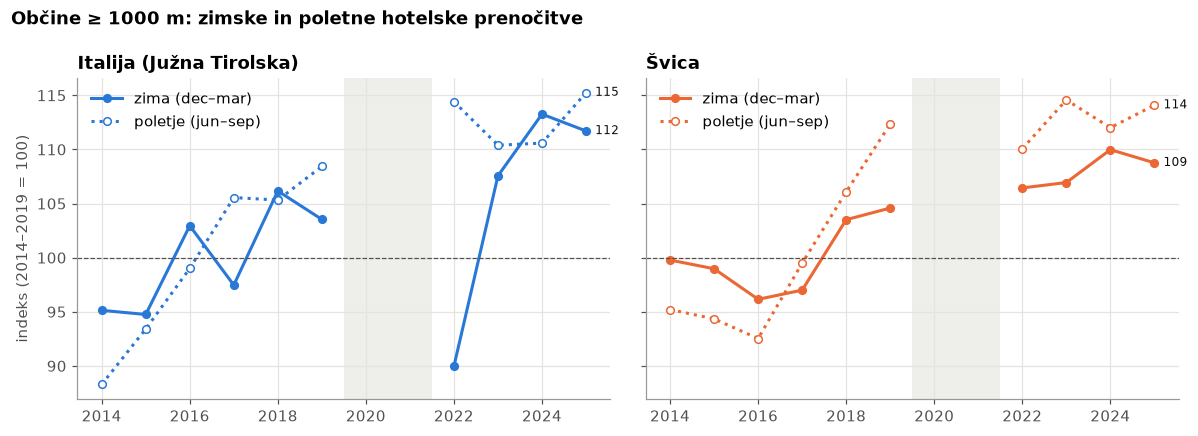

In [6]:
fig, axes = plt.subplots(1, len(COUNTRIES), figsize=(5.5 * len(COUNTRIES), 4), sharey=True, squeeze=False)
axes = axes.ravel()
for ax, c in zip(axes, COUNTRIES):
    ax.plot(win_idx.index, win_idx[c], color=COLORS[c], lw=2, marker="o", ms=5, label="zima (dec–mar)")
    ax.plot(sum_idx.index, sum_idx[c], color=COLORS[c], lw=2, marker="o", ms=5, ls=":",
            markerfacecolor="white", label="poletje (jun–sep)")
    for s, lab in [(win_idx[c], "zima"), (sum_idx[c], "poletje")]:
        ax.annotate(f"{s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK)
    ax.axhline(100, color=MUTED, lw=0.8, ls="--")
    ax.axvspan(2019.5, 2021.5, color=GRID, alpha=0.6, lw=0)
    ax.set_title(LABELS[c], loc="left")
    ax.set_xticks(range(2014, 2026, 2))
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("indeks (2014–2019 = 100)")
fig.suptitle(f"Občine ≥ {ALT_MIN} m: zimske in poletne hotelske prenočitve", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Opažanja:**
- V obeh državah sta obe sezoni po covidu nad ravnjo 2014–2019. V letu 2025 je poletje v Južni Tirolski na indeksu 115, zima na 112; v Švici poletje na 114, zima na 109.
- V Švici je poletje raslo hitreje od zime že od leta 2016 naprej (s 93 na 114), kar se ujema z rekordnimi poletji, ki jih objavlja BFS. Zima je rasla počasneje, a je bila 2024/25 tudi rekordna.
- V Južni Tirolski sta sezoni rasli podobno hitro; razlika med njima je iz leta v leto majhna in se menja.
- Zima 2022 je v Južni Tirolski še pod vplivom omejitev (indeks 90), zato je v primerjavi pred/po izpuščena.

### 2d. Sprememba sezonskosti po občinah

Vsaka točka je občina: na osi x nadmorska višina, na osi y sprememba Ginijevega koeficienta (2023–2025 minus 2013–2019). Točke pod ničlo so občine, kjer se je obisk bolj enakomerno razporedil čez leto.

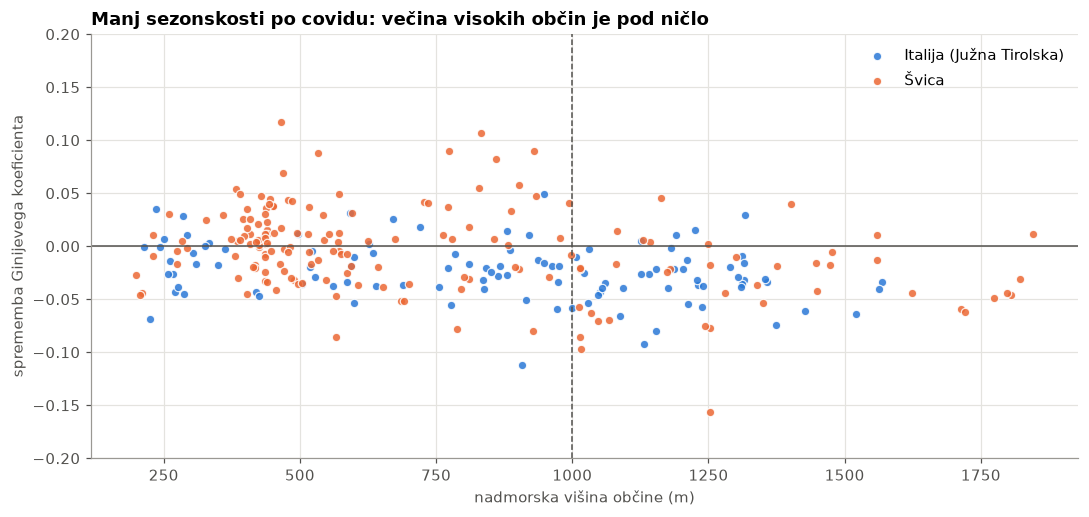

n  median_diff  share_lower
country high                                
CH      False  131        0.005        0.435
        True    40       -0.028        0.800
IT      False   62       -0.019        0.774
        True    44       -0.034        0.909

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for c in COUNTRIES:
    m = change[change["country"] == c]
    ax.scatter(m["elev_m"], m["gini_diff"], s=30, color=COLORS[c], edgecolor="white", linewidth=0.8,
               alpha=0.85, label=LABELS[c])
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(ALT_MIN, color=MUTED, lw=1, ls="--")
ax.set_ylim(-0.2, 0.2)
ax.set_xlabel("nadmorska višina občine (m)")
ax.set_ylabel("sprememba Ginijevega koeficienta")
ax.set_title("Manj sezonskosti po covidu: večina visokih občin je pod ničlo", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

out = change.groupby(["country", "high"]).agg(n=("gini_diff", "size"), median_diff=("gini_diff", "median"),
                                              share_lower=("gini_diff", lambda s: (s < 0).mean()))
out.round(3)

**Opažanja:**
- Sezonskost se je zmanjšala v 91 % visokih južnotirolskih občin in v 80 % visokih švicarskih (mediana spremembe −0,034 oz. −0,028).
- Pri nizkih občinah je slika različna: v Južni Tirolski se je sezonskost prav tako zmanjšala (77 % občin), v Švici pa ne (le 44 % občin pod ničlo, mediana +0,005).
- Zmanjšanje sezonskosti je torej lastnost predvsem gorskih in južnotirolskih občin. To formalno preverimo s hipotezo H4.

## 3. Hipoteze in izbira statističnih testov

Vse hipoteze izhajajo iz zgoraj navedenih virov ali iz zvezka 03. Enota opazovanja je **občina**.

| | Ničelna hipoteza H0 | Alternativna H1 | Vir / motivacija | Test | Zakaj ta test |
|---|---|---|---|---|---|
| H1 | zimski delež ni povezan z nadmorsko višino | višje občine imajo večji zimski delež (enostranska) | zvezek 03, literatura o smučarskem turizmu | **Spearmanova korelacija** (permutacijska p-vrednost) | odnos je monoton, ni nujno linearen; deleži niso normalno porazdeljeni |
| H2 | zimski delež visokih občin je v Italiji in Švici enak | se razlikuje (dvostranska) | primerjava držav, cilj projekta | **Mann–Whitneyjev U** | dve neodvisni skupini, majhna vzorca (44 in 40), asimetrična porazdelitev |
| H3 | zimska nestanovitnost je v vseh treh višinskih pasovih enaka | vsaj en pas se razlikuje | Falk (2010), Steiger in sod. (2019) | **Kruskal–Wallis** | tri neodvisne skupine, neparametrična različica ANOVA, velike razlike v razpršenosti |
| H4 | sezonska koncentracija (Gini) visokih občin se po covidu ni spremenila | po covidu je nižja (enostranska) | Eurac (stabilen vzorec), Bettenstopp (daljše sezone), zvezek 03 (rast izven sezone) | **Wilcoxonov test predznačenih rangov** | parni podatki (ista občina pred in po), razlike niso normalne |
| H5 | poletje in zima v visokih občinah sta po covidu rasla enako | poletje je raslo bolj (enostranska) | BFS (rekordna poletja), Serquet in Rebetez (2011) | **Wilcoxonov test predznačenih rangov** na razliki log-rasti | parni podatki, razlika dveh rasti v isti občini |

**Odločitve:**
- Stopnja značilnosti α = 0,05. Ker izvedemo več testov (vsako hipotezo za vsako državo, H2 za vsak par držav), p-vrednosti popravimo s **Holm–Bonferronijevo** metodo, da ne najdemo »značilnih« rezultatov po naključju.
- Neparametrične teste smo izbrali, ker so deleži omejeni na [0, 1], porazdelitve asimetrične in vzorci majhni (40–170 občin). Normalnosti ne predpostavljamo.
- Poleg p-vrednosti poročamo **velikost učinka** (ρ, r = |z|/√N, ε²), ker je pri nekaj sto opazovanjih lahko »značilna« tudi zanemarljivo majhna razlika.
- Omejitve: občine niso neodvisne (sosednje občine imajo isto vreme in iste goste), višine za Švico so delno nezanesljive, H5 ne vključuje temperatur (za neposreden test Serquet in Rebetez potrebujemo vremenske podatke člana 2).

In [8]:
results = []
for c in COUNTRIES:
    m = muni.loc[c]
    rho, p = spearman_test(m["elev_m"], m["winter_share"], alternative="greater")
    results.append(("H1", c, "Spearman", len(m), f"rho = {rho:.2f}", p))

for a, b in combinations(COUNTRIES, 2):   # every pair of countries
    xa = muni.loc[a].query("high")["winter_share"]
    xb = muni.loc[b].query("high")["winter_share"]
    u, p, r = mann_whitney(xa, xb)
    results.append(("H2", f"{a} vs {b}", "Mann-Whitney U", len(xa) + len(xb),
                    f"U = {u:.0f}, r = {r:.2f} (median {a} {xa.median():.0%}, {b} {xb.median():.0%})", p))

for c in COUNTRIES:
    v = vol.loc[c]
    groups = [v.loc[v["band"] == b, "winter_vol"].to_numpy() for b in ["< 600 m", "600–1000 m", "≥ 1000 m"]]
    h, p, eps = kruskal_wallis(groups)
    meds = " / ".join(f"{np.median(g):.0%}" for g in groups)
    results.append(("H3", c, "Kruskal-Wallis", len(v), f"H = {h:.1f}, eps2 = {eps:.2f} (medians {meds})", p))

for c in COUNTRIES:
    m = change[(change["country"] == c) & change["high"]]
    w, p, r = wilcoxon_signed(m["gini_diff"], alternative="less")
    results.append(("H4", c, "Wilcoxon", len(m), f"median diff = {m['gini_diff'].median():+.3f}, r = {r:.2f}", p))

for c in COUNTRIES:
    m = change[(change["country"] == c) & change["high"]].dropna(subset=["summer_minus_winter"])
    w, p, r = wilcoxon_signed(m["summer_minus_winter"], alternative="greater")
    results.append(("H5", c, "Wilcoxon", len(m),
                    f"median summer - winter = {m['summer_minus_winter'].median():+.3f} log, r = {r:.2f}", p))

res = pd.DataFrame(results, columns=["hypothesis", "group", "test", "n", "statistic / effect", "p"])
res["p_holm"] = holm(res["p"])
res["reject H0 (alpha 0.05)"] = res["p_holm"] < 0.05
pd.set_option("display.max_colwidth", 90)
res.assign(p=res["p"].map("{:.4f}".format), p_holm=res["p_holm"].map("{:.4f}".format))

,hypothesis,group,test,n,statistic / effect,p,p_holm,reject H0 (alpha 0.05)
0,H1,IT,Spearman,106,rho = 0.71,0.0001,0.0006,True
1,H1,CH,Spearman,171,rho = 0.49,0.0001,0.0006,True
2,H2,IT vs CH,Mann-Whitney U,84,"U = 624, r = 0.25 (median IT 40%, CH 45%)",0.0219,0.0656,False
3,H3,IT,Kruskal-Wallis,106,"H = 28.2, eps2 = 0.27 (medians 28% / 12% / 8%)",0.0000,0.0000,True
4,H3,CH,Kruskal-Wallis,171,"H = 8.5, eps2 = 0.05 (medians 11% / 12% / 9%)",0.0141,0.0566,False
5,H4,IT,Wilcoxon,44,"median diff = -0.034, r = 0.81",0.0000,0.0000,True
6,H4,CH,Wilcoxon,40,"median diff = -0.028, r = 0.71",0.0000,0.0000,True
7,H5,IT,Wilcoxon,44,"median summer - winter = -0.004 log, r = 0.04",0.5923,0.5923,False
8,H5,CH,Wilcoxon,40,"median summer - winter = +0.025 log, r = 0.23",0.0696,0.1393,False


**Rezultati testov** (po Holmovem popravku, α = 0,05):
- **H1 potrjena v obeh državah:** višje občine imajo večji zimski delež (ρ = 0,71 v Italiji, 0,49 v Švici; p < 0,001). Permutacijski test z 10.000 permutacijami ne more dati p, manjšega od 0,0001.
- **H2 ni potrjena:** mediana zimskega deleža visokih občin je v Italiji 40 %, v Švici 45 %. Nepopravljena p-vrednost je 0,02, po popravku 0,07. Razlike med državama ne moremo trditi; za zanesljiv sklep bi potrebovali več občin ali boljše švicarske višine.
- **H3 potrjena za Italijo, ne za Švico:** v Južni Tirolski se zimska nestanovitnost močno razlikuje med pasovi (28 % / 12 % / 8 %, ε² = 0,27). V Švici je razlika majhna (ε² = 0,05) in po popravku ni značilna (p = 0,057). To potrjuje sklep iz zvezka 03.
- **H4 potrjena v obeh državah:** sezonska koncentracija visokih občin je po covidu nižja (r = 0,81 v Italiji, 0,71 v Švici; p < 0,001). To je najmočnejši rezultat in se ujema s cilji Bettenstoppa (boljša zasedenost izven sezone).
- **H5 ni potrjena:** v visokih občinah poletje po covidu ni raslo značilno hitreje od zime (Italija mediana razlike −0,004, Švica +0,025, p = 0,14 po popravku). Poletje je v švicarskih visokih občinah sicer raslo enako kot v nizkih (mediana log-rasti 0,13), vendar je v visokih občinah rasla tudi zima (0,08 proti 0,06 v nizkih), zato razlika med sezonama ni značilna.
- Nepotrjena hipoteza ne pomeni, da je H0 resnična: pri 40–44 občinah na državo je moč testa omejena.

## Povzetek in naslednji koraki

| Hipoteza | Rezultat | Primerjava z obstoječo analizo |
|---|---|---|
| H1 višina → večji zimski delež | potrjena (IT, CH) | skladno z literaturo o smučarskem turizmu |
| H2 razlika IT–CH v zimskem deležu | ni potrjena | – |
| H3 nižje občine pozimi bolj nestanovitne | potrjena za IT, ne za CH | skladno s Falk (2010) in Steiger in sod. (2019) le za Južno Tirolsko |
| H4 sezonskost po covidu nižja | potrjena (IT, CH) | novo glede na Eurac (stabilen vzorec pred pandemijo); skladno s cilji Bettenstoppa |
| H5 poletje raste hitreje od zime | ni potrjena | rekordna poletja BFS se pokažejo, a v smučarskih občinah raste tudi zima |

**Naslednji koraki:**
- Vremenski podatki (član 2): temperatura v nižinah za test Serquet in Rebetez (junij) in snežna odeja za neposreden test H3.
- Popravek švicarskih nadmorskih višin, nato ponovitev H1–H3 za Švico.
- Za napovedni model: sezonskost se spreminja, zato model ne sme predpostaviti stalnega sezonskega vzorca (npr. trend v sezonskih deležih ali krajše učno obdobje).

**Viri:**
- Eurac Research, Sustainable Tourism Observatory of South Tyrol (STOST): letna poročila. https://webassets.eurac.edu/31538/1640244671-insto-progress-report-2021.pdf, https://insto.unwto.org/wp-content/uploads/2023/05/South-Tyrol_2022_Annual-Progress-Report.pdf, https://insto.unwto.org/wp-content/uploads/2023/11/South-Tyrol_-2023-Annual-Progress-Report.pdf
- ISTAT (2025). *I flussi turistici – anno 2024.* https://www.istat.it/comunicato-stampa/i-flussi-turistici-anno-2024/
- BFS / KMU admin (2026). *Tourism: record overnight stays in 2025.* https://www.kmu.admin.ch/en/tourism-record-overnight-stays-in-2025
- Serquet, G., & Rebetez, M. (2011). Relationship between tourism demand in the Swiss Alps and hot summer air temperatures associated with climate change. *Climatic Change*, 108(1–2), 291–300. https://doi.org/10.1007/s10584-010-0012-6
- Fernández-Morales, A. (2003). Decomposing seasonal concentration. *Annals of Tourism Research*, 30(4), 942–956. https://doi.org/10.1016/S0160-7383(03)00090-2
- stol.it: *Neue Tourismus-Leitlinien: Bettenstopp und eingeschränkter Neubau.* https://www.stol.it/artikel/wirtschaft/neue-tourismus-leitlinien-bettenstopp-und-eingeschraenkter-neubau
- Falk, M. (2010), Steiger in sod. (2019): glej zvezek 03.